# Ondas de carga espacial en un cilindro de plasma (Krall y Trivelpiece, Sección 4.8.1)
**Parte computacional del proyecto de EDP.** Mariana Lopera Correa, Computación Científica, Universidad de Medellín.

Este notebook hace tres cosas:
1. **Verifica simbólicamente (SymPy)** cada paso del desarrollo analítico: tensor dieléctrico, identidad del rotacional, laplaciano cilíndrico, reducción a la EDP 2D, ecuación de Bessel y relación de dispersión.
2. **Calcula numéricamente** las raíces $p_{n\nu}$ de las funciones de Bessel.
3. **Visualiza** los modos $E_z$ en la sección transversal del cilindro y las curvas de dispersión (Figura 4.8.3 del libro).

In [1]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from scipy.special import jv, jn_zeros
import os
sp.init_printing()
os.makedirs('figuras', exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.color': '#dddddd', 'grid.linewidth': 0.6, 'font.size': 11})
AZUL, NARANJA, AQUA, GRIS = '#2a78d6', '#eb6834', '#1baf7a', '#8a8984'

## 1. Verificación simbólica
### 1.1 Tensor dieléctrico (Paso 1, ec. 4.8.5)
Ecuación de momento linealizada con $\partial_t\to-i\omega$ y $q=e/m$, $\omega_c=eB_0/(mc)$:
$-i\omega v_x=-qE_x-\omega_c v_y,\quad -i\omega v_y=-qE_y+\omega_c v_x,\quad -i\omega v_z=-qE_z$.

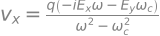

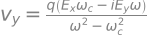

In [2]:
w, wc, q, c, n0, e, m, wp = sp.symbols('omega omega_c q c n_0 e m omega_p', positive=True)
Ex, Ey, Ez, vx, vy, vz = sp.symbols('E_x E_y E_z v_x v_y v_z')
sol = sp.solve([sp.Eq(-sp.I*w*vx, -q*Ex - wc*vy),
                sp.Eq(-sp.I*w*vy, -q*Ey + wc*vx),
                sp.Eq(-sp.I*w*vz, -q*Ez)], [vx, vy, vz])
for k_ in (vx, vy, vz):
    display(sp.Eq(k_, sp.simplify(sol[k_])))

In [3]:
# Límite B0 -> infinito (omega_c -> infinito): la velocidad transversal desaparece
print('v_x  ->', sp.limit(sol[vx], wc, sp.oo))
print('v_y  ->', sp.limit(sol[vy], wc, sp.oo))
print('v_z  =', sol[vz], ' (no depende de omega_c)')

v_x  -> 0
v_y  -> 0
v_z  = -I*E_z*q/omega  (no depende de omega_c)


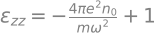

¿Coincide con 1 - wp^2/w^2? True


In [4]:
# Corriente J_z = -e n0 v_z con q = e/m, y eps_zz = 1 + (4 pi i / omega) * sigma_zz
Jz = -e*n0*sol[vz].subs(q, e/m)
eps_zz = sp.simplify((Ez + 4*sp.pi*sp.I/w*Jz)/Ez)
display(sp.Eq(sp.Symbol('epsilon_zz'), eps_zz))
# Comparar con 1 - wp^2/w^2, wp^2 = 4 pi n0 e^2 / m
print('¿Coincide con 1 - wp^2/w^2?', sp.simplify(eps_zz - (1 - (4*sp.pi*n0*e**2/m)/w**2)) == 0)

### 1.2 Identidad $\nabla\times(\nabla\times\mathbf A)=\nabla(\nabla\cdot\mathbf A)-\nabla^2\mathbf A$ (Paso 2)

In [5]:
from sympy.vector import CoordSys3D, curl, divergence, gradient
N = CoordSys3D('N')
Ax, Ay, Az = [sp.Function(n)(N.x, N.y, N.z) for n in ('A_x', 'A_y', 'A_z')]
A = Ax*N.i + Ay*N.j + Az*N.k
lap = lambda f: sum(sp.diff(f, v, 2) for v in (N.x, N.y, N.z))
izq = curl(curl(A))
der = gradient(divergence(A)) - (lap(Ax)*N.i + lap(Ay)*N.j + lap(Az)*N.k)
print('Diferencia (debe ser 0):', sp.simplify((izq - der).to_matrix(N).T))

Diferencia (debe ser 0): Matrix([[0, 0, 0]])


### 1.3 Laplaciano transversal en coordenadas cilíndricas (Apéndice A)
Se toma $f(r,\theta)$, se escribe $r=\sqrt{x^2+y^2}$, $\theta=\operatorname{atan2}(y,x)$ y se calcula $f_{xx}+f_{yy}$ por regla de la cadena.

In [6]:
x, y = sp.symbols('x y', real=True)
r, th = sp.symbols('r theta', positive=True)
f = sp.Function('f')
F = f(sp.sqrt(x**2 + y**2), sp.atan2(y, x))
lap_xy = sp.diff(F, x, 2) + sp.diff(F, y, 2)
lap_pol = lap_xy.subs({x: r*sp.cos(th), y: r*sp.sin(th)})
lap_pol = sp.simplify(lap_pol.doit())
esperado = sp.diff(f(r, th), r, 2) + sp.diff(f(r, th), r)/r + sp.diff(f(r, th), th, 2)/r**2
# Comparamos usando una función de prueba concreta (polinomio * trigonometría)
prueba = lambda R, T: R**3*sp.cos(2*T) + R*sp.sin(T)
g = prueba(sp.sqrt(x**2+y**2), sp.atan2(y, x))
lap_g = (sp.diff(g, x, 2) + sp.diff(g, y, 2)).subs({x: r*sp.cos(th), y: r*sp.sin(th)})
G = prueba(r, th)
lap_g_pol = sp.diff(G, r, 2) + sp.diff(G, r)/r + sp.diff(G, th, 2)/r**2
print('Cartesiano vs. fórmula cilíndrica (debe ser 0):', sp.simplify(sp.expand_trig(lap_g - lap_g_pol)))

Cartesiano vs. fórmula cilíndrica (debe ser 0): 0


### 1.4 De la ecuación cerrada (4.8.7 + 4.8.9) a la EDP 2D (4.8.11)
Ecuación cerrada: $\nabla_T^2E_z+\partial_z^2E_z+\frac{\omega^2}{c^2}\left(1-\frac{\omega_p^2}{\omega^2}\right)E_z-\frac{\omega_p^2}{\omega^2}\partial_z^2E_z=0$, con $E_z=R(r)\Theta(\theta)e^{i(kz-\omega t)}$.

In [7]:
z, t, k = sp.symbols('z t k', real=True)
R, Th = sp.Function('R'), sp.Function('Theta')
Ezf = R(r)*Th(th)*sp.exp(sp.I*(k*z - w*t))
lapT = lambda u: sp.diff(u, r, 2) + sp.diff(u, r)/r + sp.diff(u, th, 2)/r**2
K = 1 - wp**2/w**2
cerrada = lapT(Ezf) + sp.diff(Ezf, z, 2) + w**2/c**2*K*Ezf - wp**2/w**2*sp.diff(Ezf, z, 2)
T2 = (w**2/c**2 - k**2)*K
eq_4_8_11 = lapT(R(r)*Th(th)) + T2*R(r)*Th(th)
print('cerrada / exp(i(kz-wt)) - [lap_T + T^2] (debe ser 0):',
      sp.simplify(sp.expand(cerrada/sp.exp(sp.I*(k*z - w*t)) - eq_4_8_11)))

cerrada / exp(i(kz-wt)) - [lap_T + T^2] (debe ser 0): 0


### 1.5 Separación de variables y ecuación de Bessel
Con $\Theta=e^{-in\theta}$ se verifica que $R=J_n(Tr)$ satisface $r^2R''+rR'+(T^2r^2-n^2)R=0$, y que $\hat E_z=J_n(Tr)e^{-in\theta}$ satisface la EDP 2D.

In [8]:
n = sp.Symbol('n', integer=True, nonnegative=True)
T = sp.Symbol('T', positive=True)
Rb = sp.besselj(n, T*r)
radial = r**2*sp.diff(Rb, r, 2) + r*sp.diff(Rb, r) + (T**2*r**2 - n**2)*Rb
print('EDO radial con J_n(Tr):', sp.simplify(radial))
Ehat = sp.besselj(n, T*r)*sp.exp(-sp.I*n*th)
print('Helmholtz con J_n(Tr) e^{-in theta}:', sp.simplify(lapT(Ehat) + T**2*Ehat))
# Y_n diverge en r = 0:
for nn in (0, 1, 2):
    print(f'n={nn}:  J_n(0) = {sp.besselj(nn, 0)},   lim Y_n(x), x->0+ =', sp.limit(sp.bessely(nn, x), x, 0, '+'))

EDO radial con J_n(Tr): 0


Helmholtz con J_n(Tr) e^{-in theta}: 0
n=0:  J_n(0) = 1,   lim Y_n(x), x->0+ = -oo
n=1:  J_n(0) = 0,   lim Y_n(x), x->0+ = -oo
n=2:  J_n(0) = 0,   lim Y_n(x), x->0+ = -oo


### 1.6 Relación de dispersión (4.8.15)
Igualamos $T^2=\left(\frac{\omega^2}{c^2}-k^2\right)\left(1-\frac{\omega_p^2}{\omega^2}\right)$ con $T^2=p_{n\nu}^2/a^2$ y despejamos $k^2$ y luego $\omega^2$.

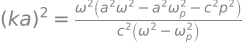

¿Igual a 4.8.15? True


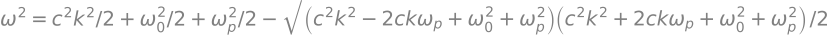

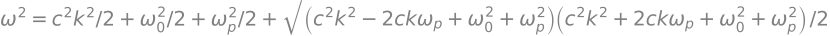

In [9]:
a, p = sp.symbols('a p', positive=True)
k2 = sp.Symbol('k2')
sol_k2 = sp.solve(sp.Eq((w**2/c**2 - k2)*K, p**2/a**2), k2)[0]
display(sp.Eq(sp.Symbol('(ka)^2'), sp.simplify(sol_k2*a**2)))
print('¿Igual a 4.8.15?', sp.simplify(sol_k2*a**2 - (w**2*a**2/c**2 - p**2/(1 - wp**2/w**2))) == 0)
# Despeje de omega^2 (dos ramas)
X = sp.Symbol('X', positive=True)
w0 = sp.Symbol('omega_0', positive=True)
ramas = sp.solve(sp.expand((X - c**2*k**2)*(X - wp**2) - w0**2*X), X)
for s_ in ramas: display(sp.Eq(sp.Symbol('omega^2'), s_))

## 2. Raíces de las funciones de Bessel $p_{n\nu}$
La condición $E_z(r=a)=0$ exige $J_n(Ta)=0$. `scipy.special.jn_zeros` usa un método iterativo (Newton sobre aproximaciones asintóticas). Abajo, además, las calculamos con nuestro propio método de bisección para comparar.

In [10]:
def bisec(fun, lo, hi, tol=1e-12):
    flo = fun(lo)
    while hi - lo > tol:
        mid = 0.5*(lo + hi); fm = fun(mid)
        if np.sign(fm) == np.sign(flo): lo, flo = mid, fm
        else: hi = mid
    return 0.5*(lo + hi)

def ceros_bessel(nn, cuantos, paso=0.1):
    # barrido para encontrar cambios de signo y bisección en cada intervalo
    raices, xa = [], 1e-6
    while len(raices) < cuantos:
        xb = xa + paso
        if np.sign(jv(nn, xa)) != np.sign(jv(nn, xb)):
            raices.append(bisec(lambda s: jv(nn, s), xa, xb))
        xa = xb
    return np.array(raices)

print(' n | ' + ' | '.join(f'p_n{v}' for v in (1, 2, 3)) + ' | error máx. vs scipy')
for nn in range(4):
    propias, ref = ceros_bessel(nn, 3), jn_zeros(nn, 3)
    print(f' {nn} | ' + ' | '.join(f'{v:7.4f}' for v in propias) + f' | {np.max(np.abs(propias - ref)):.1e}')

 n | p_n1 | p_n2 | p_n3 | error máx. vs scipy
 0 |  2.4048 |  5.5201 |  8.6537 | 3.1e-13
 1 |  3.8317 |  7.0156 | 10.1735 | 3.0e-13
 2 |  5.1356 |  8.4172 | 11.6198 | 3.2e-13
 3 |  6.3802 |  9.7610 | 13.0152 | 3.5e-13


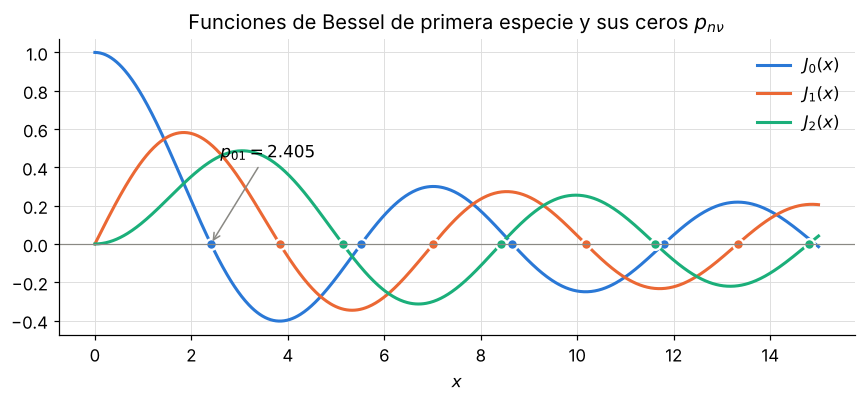

In [11]:
xs = np.linspace(0, 15, 800)
fig, ax = plt.subplots(figsize=(8, 3.8))
for nn, col in zip((0, 1, 2), (AZUL, NARANJA, AQUA)):
    ax.plot(xs, jv(nn, xs), color=col, lw=2, label=f'$J_{nn}(x)$')
    zs = jn_zeros(nn, 4); zs = zs[zs < 15]
    ax.plot(zs, 0*zs, 'o', color=col, ms=7, mec='white', mew=1.5)
ax.axhline(0, color=GRIS, lw=0.8)
ax.annotate('$p_{01}=2.405$', (2.405, 0), (2.6, 0.45), arrowprops=dict(arrowstyle='->', color=GRIS))
ax.set_xlabel('$x$'); ax.set_title('Funciones de Bessel de primera especie y sus ceros $p_{n\\nu}$')
ax.legend(frameon=False); fig.tight_layout(); fig.savefig('figuras/bessel_ceros.png', dpi=200); plt.show()

## 3. Los modos: $E_z$ en la sección transversal del cilindro
$\hat E_z(r,\theta)=J_n\!\left(p_{n\nu}\,r/a\right)\cos(n\theta)$ (parte real). Rojo = campo hacia $+z$, azul = hacia $-z$, blanco = nodo. Todos los modos se anulan en la pared $r=a$.

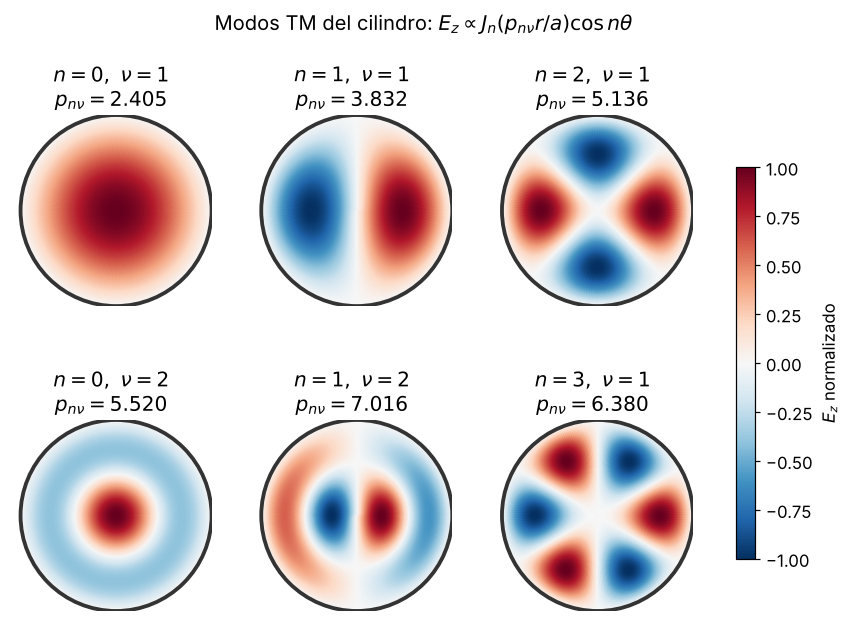

In [12]:
def modo(nn, nu, Npts=300, a_=1.0):
    pz = jn_zeros(nn, nu)[-1]
    rr = np.linspace(0, a_, Npts); tt = np.linspace(0, 2*np.pi, Npts)
    RR, TT = np.meshgrid(rr, tt)
    Z = jv(nn, pz*RR/a_)*np.cos(nn*TT)
    return RR*np.cos(TT), RR*np.sin(TT), Z/np.abs(Z).max(), pz

modos = [(0, 1), (1, 1), (2, 1), (0, 2), (1, 2), (3, 1)]
fig, axs = plt.subplots(2, 3, figsize=(10, 6.6))
for ax, (nn, nu) in zip(axs.flat, modos):
    X_, Y_, Z_, pz = modo(nn, nu)
    im = ax.pcolormesh(X_, Y_, Z_, cmap='RdBu_r', vmin=-1, vmax=1, shading='gouraud')
    ax.add_patch(plt.Circle((0, 0), 1, fill=False, lw=2.5, color='#333333'))
    ax.set_aspect('equal'); ax.axis('off')
    ax.set_title(f'$n={nn},\\ \\nu={nu}$\n$p_{{n\\nu}}={pz:.3f}$')
fig.colorbar(im, ax=axs, shrink=0.7, label='$E_z$ normalizado')
fig.suptitle('Modos TM del cilindro: $E_z \\propto J_n(p_{n\\nu} r/a)\\cos n\\theta$')
fig.savefig('figuras/modos_seccion.png', dpi=200, bbox_inches='tight'); plt.show()

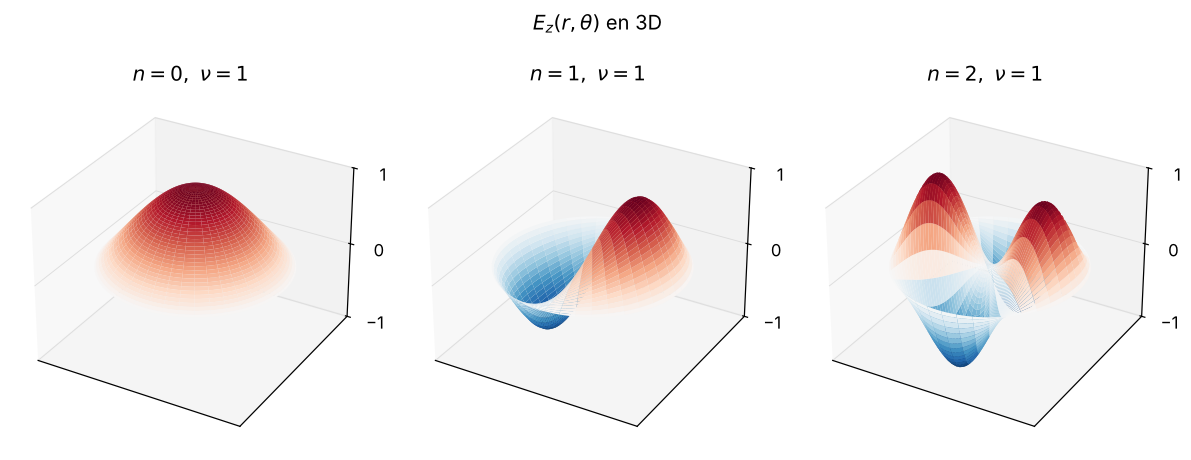

In [13]:
# Vista 3D del modo (1,1): superficie de E_z sobre el disco
from mpl_toolkits.mplot3d import Axes3D  # noqa
fig = plt.figure(figsize=(11, 4.5))
for i, (nn, nu) in enumerate([(0, 1), (1, 1), (2, 1)]):
    ax = fig.add_subplot(1, 3, i+1, projection='3d')
    X_, Y_, Z_, pz = modo(nn, nu, Npts=120)
    ax.plot_surface(X_, Y_, Z_, cmap='RdBu_r', vmin=-1, vmax=1, linewidth=0, antialiased=True)
    ax.set_title(f'$n={nn},\\ \\nu={nu}$'); ax.set_zlim(-1, 1)
    ax.set_xticks([]); ax.set_yticks([]); ax.set_zticks([-1, 0, 1])
fig.suptitle('$E_z(r,\\theta)$ en 3D')
fig.tight_layout(); fig.savefig('figuras/modos_3d.png', dpi=200); plt.show()

## 4. Curvas de dispersión (Figura 4.8.3)
En unidades normalizadas $\Omega=\omega/\omega_p$, $K=ck/\omega_p$, $\Omega_0=\omega_0/\omega_p$ con $\omega_0=p_{n\nu}c/a$:
$$\Omega^2=\frac{S\pm\sqrt{S^2-4K^2}}{2},\qquad S=1+\Omega_0^2+K^2.$$
El único parámetro físico es $\omega_p a/c$ (qué tan denso es el plasma comparado con el tamaño del tubo).

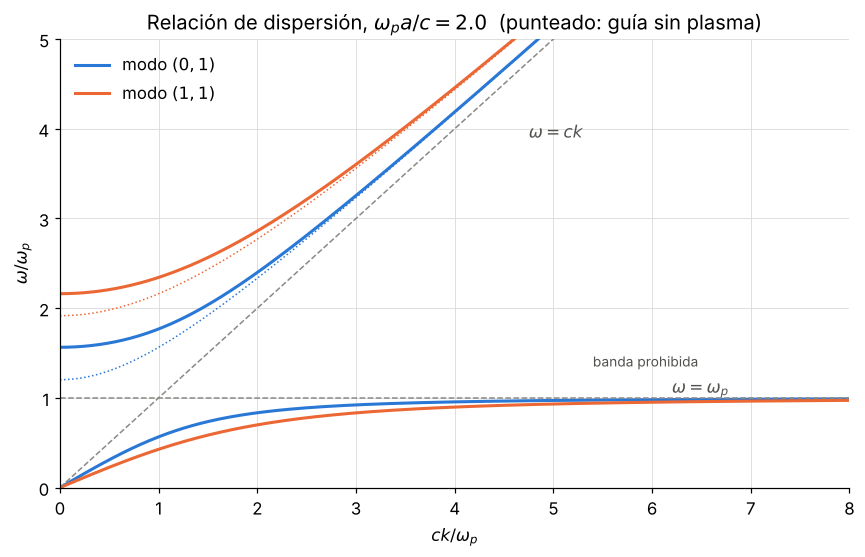

In [14]:
def ramas_disp(K, Om0):
    S = 1 + Om0**2 + K**2
    raiz = np.sqrt(S**2 - 4*K**2)
    return np.sqrt((S + raiz)/2), np.sqrt((S - raiz)/2)

wpa_c = 2.0                      # omega_p a / c (parámetro elegido)
K = np.linspace(0, 8, 600)
fig, ax = plt.subplots(figsize=(8, 5.2))
for (nn, nu), col in zip([(0, 1), (1, 1)], (AZUL, NARANJA)):
    Om0 = jn_zeros(nn, nu)[-1]/wpa_c
    sup, inf = ramas_disp(K, Om0)
    ax.plot(K, sup, color=col, lw=2, label=f'modo $({nn},{nu})$')
    ax.plot(K, inf, color=col, lw=2)
    ax.plot(K, np.sqrt(Om0**2 + K**2), color=col, lw=1, ls=':')   # guía vacía
ax.plot(K, K, color=GRIS, lw=1, ls='--'); ax.text(4.75, 3.9, '$\\omega = ck$', color='#52514e')
ax.axhline(1, color=GRIS, lw=1, ls='--'); ax.text(6.2, 1.05, '$\\omega=\\omega_p$', color='#52514e')
ax.text(5.4, 1.35, 'banda prohibida', color='#52514e', fontsize=9)
ax.set_xlim(0, 8); ax.set_ylim(0, 5)
ax.set_xlabel('$ck/\\omega_p$'); ax.set_ylabel('$\\omega/\\omega_p$')
ax.set_title(f'Relación de dispersión, $\\omega_p a/c={wpa_c}$  (punteado: guía sin plasma)')
ax.legend(frameon=False, loc='upper left'); fig.tight_layout()
fig.savefig('figuras/dispersion.png', dpi=200); plt.show()

In [15]:
# Comprobaciones numéricas de las fórmulas del documento
for (nn, nu) in [(0, 1), (1, 1)]:
    Om0 = jn_zeros(nn, nu)[-1]/wpa_c
    sup, inf = ramas_disp(np.array([0.0, 1e-4]), Om0)
    print(f'modo ({nn},{nu}): corte numérico = {sup[0]:.4f},  sqrt(1+Om0^2) = {np.sqrt(1+Om0**2):.4f};  '
          f'pendiente baja = {inf[1]/1e-4:.4f},  1/sqrt(1+Om0^2) = {1/np.sqrt(1+Om0**2):.4f}')
# Verificar que los puntos calculados cumplen 4.8.15
Om0 = jn_zeros(0, 1)[0]/wpa_c; Kt = 2.5
for Om in ramas_disp(Kt, Om0):
    ka2_der = Om**2*wpa_c**2 - jn_zeros(0, 1)[0]**2/(1 - 1/Om**2)
    print(f'Omega = {Om:.4f}:  (ka)^2 = {Kt**2*wpa_c**2:.6f}   lado derecho de 4.8.15 = {ka2_der:.6f}')

modo (0,1): corte numérico = 1.5639,  sqrt(1+Om0^2) = 1.5639;  pendiente baja = 0.6394,  1/sqrt(1+Om0^2) = 0.6394
modo (1,1): corte numérico = 2.1611,  sqrt(1+Om0^2) = 2.1611;  pendiente baja = 0.4627,  1/sqrt(1+Om0^2) = 0.4627
Omega = 2.8116:  (ka)^2 = 25.000000   lado derecho de 4.8.15 = 25.000000
Omega = 0.8892:  (ka)^2 = 25.000000   lado derecho de 4.8.15 = 25.000000


## 5. Efecto de la densidad del plasma
Al aumentar $\omega_p a/c$ (plasma más denso o tubo más ancho), la rama inferior se acerca a $\omega_p$ más rápido y el corte de la rama superior sube.

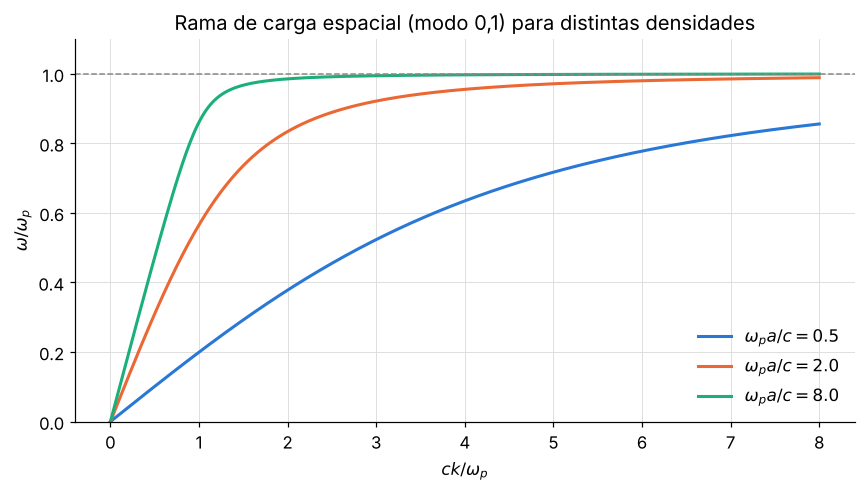

In [16]:
fig, ax = plt.subplots(figsize=(8, 4.6))
p01 = jn_zeros(0, 1)[0]
for wpa, col in zip((0.5, 2.0, 8.0), (AZUL, NARANJA, AQUA)):
    sup, inf = ramas_disp(K, p01/wpa)
    ax.plot(K, inf, color=col, lw=2, label=f'$\\omega_p a/c={wpa}$')
ax.axhline(1, color=GRIS, lw=1, ls='--')
ax.set_xlabel('$ck/\\omega_p$'); ax.set_ylabel('$\\omega/\\omega_p$'); ax.set_ylim(0, 1.1)
ax.set_title('Rama de carga espacial (modo 0,1) para distintas densidades')
ax.legend(frameon=False); fig.tight_layout(); fig.savefig('figuras/dispersion_densidad.png', dpi=200); plt.show()

## 6. Animación: la onda propagándose a lo largo del cilindro
Corte longitudinal $(r,z)$ del modo $(0,1)$ en la rama inferior: $E_z=J_0(p_{01}r/a)\cos(kz-\omega t)$.

In [17]:
from matplotlib.animation import FuncAnimation
from IPython.display import HTML
plt.rcParams['animation.html'] = 'jshtml'
Kt = 2.0; Om = ramas_disp(Kt, p01/wpa_c)[1]
zz = np.linspace(0, 4*np.pi/Kt, 300); rr = np.linspace(-1, 1, 120)
ZZ, RR = np.meshgrid(zz, rr)
fig, ax = plt.subplots(figsize=(8, 2.8))
mesh = ax.pcolormesh(ZZ, RR, jv(0, p01*np.abs(RR))*np.cos(Kt*ZZ), cmap='RdBu_r', vmin=-1, vmax=1, shading='auto')
ax.axhline(1, color='#333333', lw=3); ax.axhline(-1, color='#333333', lw=3)
ax.set_xlabel('$z$'); ax.set_ylabel('$r/a$'); ax.grid(False)
ax.set_title(f'Modo (0,1), $\\omega/\\omega_p={Om:.3f}$')
def anim(i):
    tt = i*2*np.pi/Om/40
    mesh.set_array((jv(0, p01*np.abs(RR))*np.cos(Kt*ZZ - Om*tt)).ravel()); return (mesh,)
an = FuncAnimation(fig, anim, frames=40, interval=60, blit=True); plt.close(fig)
HTML(an.to_jshtml())